In [ ]:
import numpy as np
import pandas as pd

# Set random seed
np.random.seed(42)

# Number of samples
n_samples = 500

# Generate Features
Square_Footage = np.random.normal(2100, 500, n_samples).clip(800, 4500)

Number_of_Bedrooms = np.random.choice(
    [1, 2, 3, 4, 5],
    size=n_samples,
    p=[0.10, 0.25, 0.40, 0.20, 0.05]
)

Distance_to_Transit_km = np.random.exponential(
    scale=4,
    size=n_samples
).clip(0.5, 20)

Age_of_Property = np.random.uniform(
    1,
    40,
    n_samples
)

School_Rating = np.random.uniform(
    3.0,
    9.8,
    n_samples
)

# Generate Noise
noise = np.random.normal(
    0,
    25000,
    n_samples
)

# Generate Target Variable
House_Price = (
    (150 * Square_Footage)
    + (12000 * Number_of_Bedrooms)
    - (8500 * Distance_to_Transit_km)
    - (1500 * Age_of_Property)
    + (9000 * School_Rating)
    + 50000
    + noise
)

# Create DataFrame
df = pd.DataFrame({
    "Square_Footage": Square_Footage,
    "Number_of_Bedrooms": Number_of_Bedrooms,
    "Distance_to_Transit_km": Distance_to_Transit_km,
    "Age_of_Property": Age_of_Property,
    "School_Rating": School_Rating,
    "House_Price": House_Price
})

# Display Dataset
print("First 5 Rows:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nDataset Information:")
print(df.info())

print("\nStatistical Summary:")
print(df.describe())

# Save Dataset
df.to_csv("house_price_dataset.csv", index=False)

print("\nDataset saved successfully as 'house_price_dataset.csv'")

First 5 Rows:
   Square_Footage  Number_of_Bedrooms  Distance_to_Transit_km  \
0     2348.357077                   3                8.218013   
1     2030.867849                   3                0.500000   
2     2423.844269                   3                6.990590   
3     2861.514928                   5                0.551856   
4     1982.923313                   3                1.632588   

   Age_of_Property  School_Rating    House_Price  
0        16.482279       6.062387  413793.688284  
1        18.440899       8.092019  403076.172670  
2        24.423179       7.427804  446349.887943  
3        21.111498       7.222314  565975.941025  
4        36.856287       5.396150  379604.431221  

Dataset Shape:
(500, 6)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Square_Footage          500

In [ ]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Square_Footage          500 non-null    float64
 1   Number_of_Bedrooms      500 non-null    int64  
 2   Distance_to_Transit_km  500 non-null    float64
 3   Age_of_Property         500 non-null    float64
 4   School_Rating           500 non-null    float64
 5   House_Price             500 non-null    float64
dtypes: float64(5), int64(1)
memory usage: 23.6 KB
None


In [ ]:
df.head()

,Square_Footage,Number_of_Bedrooms,Distance_to_Transit_km,Age_of_Property,School_Rating,House_Price
0,2348.357077,3,8.218013,16.482279,6.062387,413793.688284
1,2030.867849,3,0.500000,18.440899,8.092019,403076.172670
2,2423.844269,3,6.990590,24.423179,7.427804,446349.887943
3,2861.514928,5,0.551856,21.111498,7.222314,565975.941025
4,1982.923313,3,1.632588,36.856287,5.396150,379604.431221


In [ ]:
print(df.isnull().sum())

Square_Footage            0
Number_of_Bedrooms        0
Distance_to_Transit_km    0
Age_of_Property           0
School_Rating             0
House_Price               0
dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm
import pandas as pd
import numpy as np

# Independent Variables
X = df[
    [
        "Square_Footage",
        "Number_of_Bedrooms",
        "Distance_to_Transit_km",
        "Age_of_Property",
        "School_Rating"
    ]
]

# Dependent Variable
Y = df["House_Price"]

# Split the dataset
X_train, X_test, Y_train, Y_test = train_test_split(
    X,
    Y,
    test_size=0.20,
    random_state=42
)

print("Training Set Shape:", X_train.shape)
print("Testing Set Shape :", X_test.shape)

Training Set Shape: (400, 5)
Testing Set Shape : (100, 5)


In [ ]:
model = LinearRegression()

model.fit(X_train, Y_train)

intercept = model.intercept_

coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient (Beta)": model.coef_
})

print("\nIntercept (Beta_0):")
print(intercept)

print("\nLearned Feature Coefficients:")
print(coefficients)


Intercept (Beta_0):
57402.07628283085

Learned Feature Coefficients:
                  Feature  Coefficient (Beta)
0          Square_Footage          147.157128
1      Number_of_Bedrooms        11619.863559
2  Distance_to_Transit_km        -8310.489334
3         Age_of_Property        -1554.814105
4           School_Rating         9119.073510


In [ ]:
Y_pred = model.predict(X_test)

mae = mean_absolute_error(Y_test, Y_pred)

mse = mean_squared_error(Y_test, Y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(Y_test, Y_pred)

# Adjusted R²
n = len(Y_test)

p = X_test.shape[1]

adj_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)

print("\n-------------------------------")
print("MODEL PERFORMANCE METRICS")
print("-------------------------------")

print("Mean Absolute Error (MAE):", mae)
print("Mean Squared Error (MSE):", mse)
print("Root Mean Squared Error (RMSE):", rmse)
print("R² Score:", r2)
print("Adjusted R²:", adj_r2)


-------------------------------
MODEL PERFORMANCE METRICS
-------------------------------
Mean Absolute Error (MAE): 18595.438227401984
Mean Squared Error (MSE): 494425957.78969055
Root Mean Squared Error (RMSE): 22235.69107965144
R² Score: 0.9118601549699549
Adjusted R²: 0.9071718653406972


In [ ]:
# Residuals
residuals = Y_test - Y_pred

# VIF Calculation
vif_data = pd.DataFrame()

vif_data["Feature"] = X.columns

vif_data["VIF"] = [
    variance_inflation_factor(X.values, i)
    for i in range(X.shape[1])
]

print("\n-------------------------------")
print("VARIANCE INFLATION FACTOR (VIF)")
print("-------------------------------")

print(vif_data)

# OLS Summary
X_train_sm = sm.add_constant(X_train)

ols_model = sm.OLS(Y_train, X_train_sm).fit()

print("\nOLS SUMMARY")
print(ols_model.summary())


-------------------------------
VARIANCE INFLATION FACTOR (VIF)
-------------------------------
                  Feature        VIF
0          Square_Footage  11.274181
1      Number_of_Bedrooms   7.765099
2  Distance_to_Transit_km   2.035990
3         Age_of_Property   4.022520
4           School_Rating   8.971319

OLS SUMMARY
                            OLS Regression Results                            
Dep. Variable:            House_Price   R-squared:                       0.921
Model:                            OLS   Adj. R-squared:                  0.920
Method:                 Least Squares   F-statistic:                     917.9
Date:                Wed, 05 Aug 2026   Prob (F-statistic):          1.47e-214
Time:                        05:28:40   Log-Likelihood:                -4618.6
No. Observations:                 400   AIC:                             9249.
Df Residuals:                     394   BIC:                             9273.
Df Model:                           

In [ ]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm

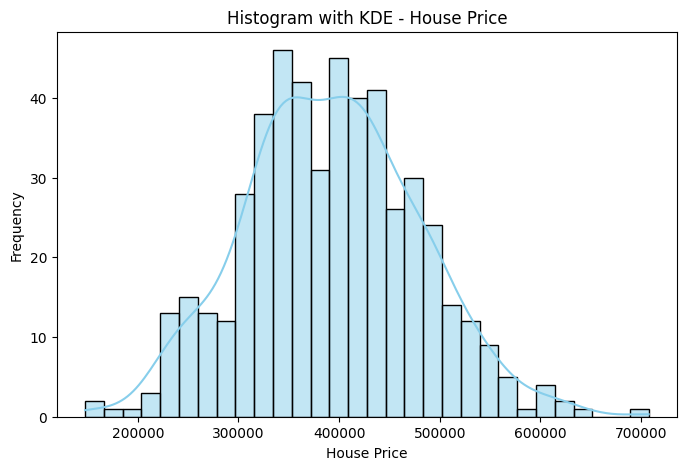

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,5))

sns.histplot(
    data=df,
    x="House_Price",
    bins=30,
    kde=True,
    color="skyblue"
)

plt.title("Histogram with KDE - House Price")
plt.xlabel("House Price")
plt.ylabel("Frequency")

plt.show()

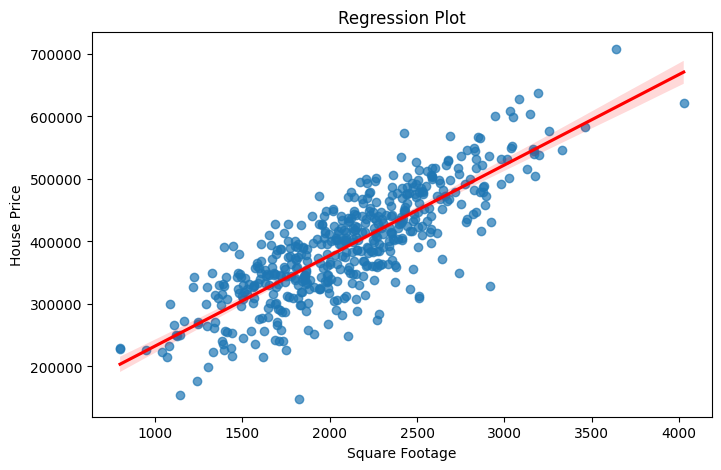

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,5))

sns.regplot(
    x="Square_Footage",
    y="House_Price",
    data=df,
    scatter_kws={"alpha":0.7},
    line_kws={"color":"red"}
)

plt.title("Regression Plot")
plt.xlabel("Square Footage")
plt.ylabel("House Price")

plt.show()

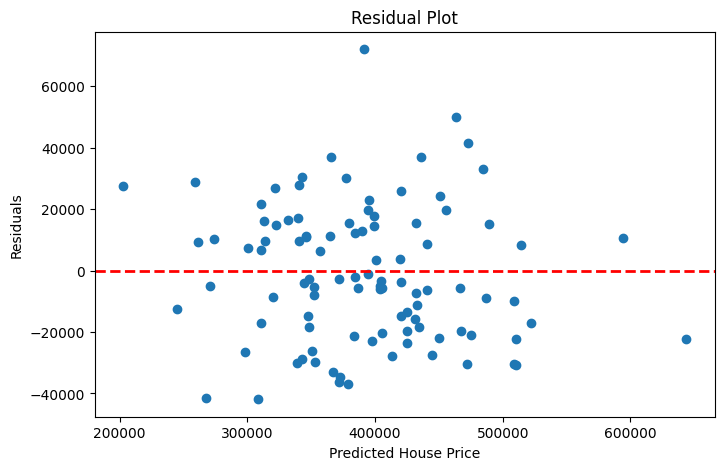

In [ ]:
import matplotlib.pyplot as plt

residuals = Y_test - Y_pred

plt.figure(figsize=(8,5))

plt.scatter(
    Y_pred,
    residuals
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    linewidth=2
)

plt.title("Residual Plot")
plt.xlabel("Predicted House Price")
plt.ylabel("Residuals")

plt.show()